***1. Import***

In [1]:
import pandas as pd
import numpy as np
import shap
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, precision_recall_curve, average_precision_score,
    roc_curve, auc, recall_score, precision_score
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

!pip install lime
from lime.lime_tabular import LimeTabularExplainer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=fce9c4bbfe4dcfa44f98437004d4c6380d55df337697851377561cb66fddb280
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


***2. Load Data***

In [2]:
data = pd.read_csv("/content/drive/MyDrive/coding/Ratul bhais paper.csv")

print("data shape:", data.shape)
print(data.head())
print(data.columns)

target_col = "cardiovascular disease"   # change if your column name is different

# drop rows where the target is missing
data = data.dropna(subset=[target_col])

print("after dropping NaN in target, shape:", data.shape)
print(data[target_col].unique())

data shape: (70000, 13)
   Gender  age  height  weight(kg)        BMI  High BP  Low BP  cholesterol  \
0       1   50     168        62.0  21.967120      110      80            1   
1       0   55     156        85.0  34.927679      140      90            3   
2       0   52     165        64.0  23.507805      130      70            3   
3       1   48     169        82.0  28.710479      150     100            1   
4       0   48     156        56.0  23.011177      100      60            1   

   Glucose  smoking  alcohol  active  cardiovascular disease  
0        1        0        0       1                       0  
1        1        0        0       1                       1  
2        1        0        0       0                       1  
3        1        0        0       1                       1  
4        1        0        0       0                       0  
Index(['Gender', 'age', 'height', 'weight(kg)', 'BMI', 'High BP', 'Low BP',
       'cholesterol', 'Glucose', 'smoking', 'al

***3. Define features (X) and label (y) + cleaning***

In [3]:
feature_cols = [
    "Gender", "age", "height", "weight(kg)", "BMI",
    "High BP", "Low BP", "cholesterol", "Glucose",
    "smoking", "alcohol", "active"
]

# Drop rows where any of the feature values is missing
data = data.dropna(subset=feature_cols)
print("After dropping NaN in features:", data.shape)

# Simple automatic outlier trimming using extreme quantiles
num_cols = ["age", "height", "weight(kg)", "BMI",
            "High BP", "Low BP", "cholesterol", "Glucose"]

for col in num_cols:
    low_q, high_q = data[col].quantile([0.001, 0.999])  # keep 0.1%–99.9%
    data = data[(data[col] >= low_q) & (data[col] <= high_q)]

print("After trimming extreme outliers:", data.shape)

X = data[feature_cols]                      # all rows, 12 columns
y = data[target_col].astype(int)           # make sure it is integer 0/1

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique labels in y:", y.unique())

After dropping NaN in features: (70000, 13)
After trimming extreme outliers: (69394, 13)
X shape: (69394, 12)
y shape: (69394,)
Unique labels in y: [0 1]


***4. Correlation Matrix***

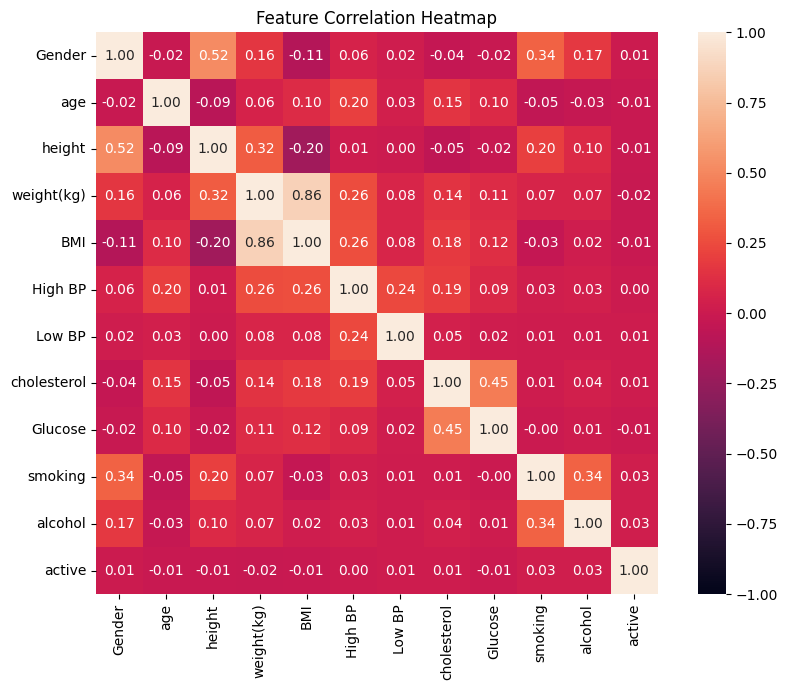

In [4]:
corr = X.corr()

rocket_cmap = sns.color_palette("rocket", as_cmap=True)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=rocket_cmap,
    vmin=-1, vmax=1,
    square=True
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

***5. Train/test split (80/20)%***

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (55515, 12) Test: (13879, 12)


***6. Hyperparameter-tuned Neural Network (MLP)***

In [6]:
base_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        max_iter=500,
        random_state=42
    ))
])

param_dist = {
    "mlp__hidden_layer_sizes": [
        (16, 16),
        (32, 16),
        (32, 32),
        (64, 32)
    ],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [1e-5, 1e-4, 1e-3],
    "mlp__learning_rate_init": [1e-3, 3e-3, 1e-2],
    "mlp__solver": ["adam"],
}

nn_search = RandomizedSearchCV(
    base_pipe,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=2
)

print("Fitting hyperparameter search for NN...")
nn_search.fit(X_train, y_train)

print("Best NN params:", nn_search.best_params_)
print("Best CV AUC   :", nn_search.best_score_)

Fitting hyperparameter search for NN...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best NN params: {'mlp__solver': 'adam', 'mlp__learning_rate_init': 0.001, 'mlp__hidden_layer_sizes': (16, 16), 'mlp__alpha': 1e-05, 'mlp__activation': 'relu'}
Best CV AUC   : 0.7981301403041958


In [7]:
# Use the best NN as our final model for everything else
model = nn_search.best_estimator_

# Evaluate tuned NN on the test set
y_proba = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

test_auc = roc_auc_score(y_test, y_proba)
test_acc = accuracy_score(y_test, y_pred)

print(f"Tuned NN test AUC: {test_auc:.3f}")
print(f"Tuned NN test acc: {test_acc:.3f}")

Tuned NN test AUC: 0.802
Tuned NN test acc: 0.736


***7. Accuracy of the NN model***

In [8]:
#Accuracy of the model
acc = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {acc:.3f}")

Test accuracy: 0.736


***8. Confusion Matrix***

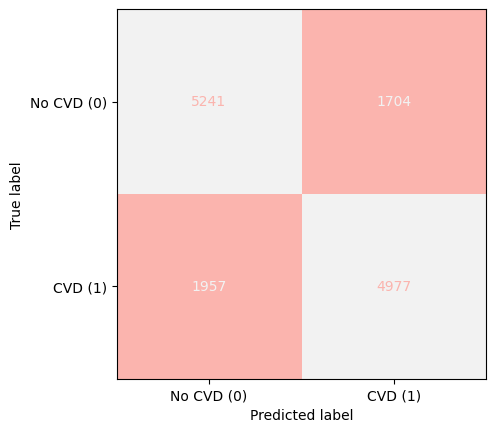

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No CVD (0)", "CVD (1)"]
)

base_cmap = plt.cm.Blues
light_colors = base_cmap(np.linspace(0.1, 0.6, 256))
light_cmap = ListedColormap(light_colors)

disp.plot(
    cmap="Pastel1",      # or "Pastel2"
    values_format="d",
    colorbar=False
)
plt.show()

***9. Extra metrics: classification report + PR curve***

              precision    recall  f1-score   support

           0      0.728     0.755     0.741      6945
           1      0.745     0.718     0.731      6934

    accuracy                          0.736     13879
   macro avg      0.737     0.736     0.736     13879
weighted avg      0.737     0.736     0.736     13879

Average precision (AP / PR-AUC): 0.785


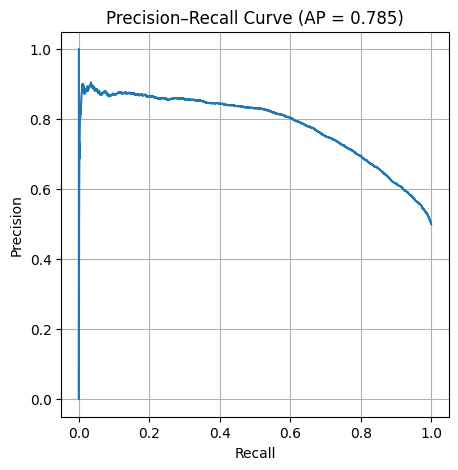

In [10]:
print(classification_report(y_test, y_pred, digits=3))

precision, recall, thresh_pr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)
print(f"Average precision (AP / PR-AUC): {ap:.3f}")

plt.figure(figsize=(5, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve (AP = {ap:.3f})")
plt.grid(True)
plt.show()

***10. ROC + AUC curve***

AUC: 0.802


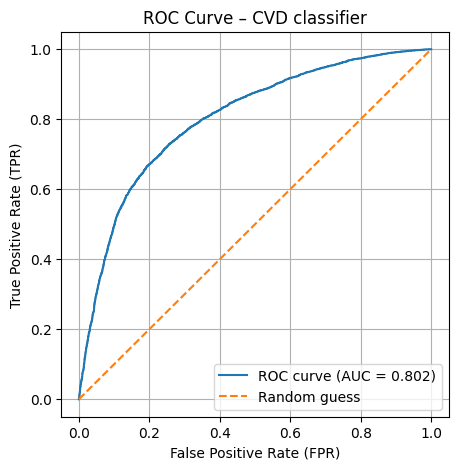

In [11]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
print(f"AUC: {roc_auc:.3f}")

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve – CVD classifier")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

#11. LIME code

***i. Build the LIME explainer***

In [12]:
# Convert train / test to NumPy for LIME
X_train_np = X_train.values
X_test_np  = X_test.values

# Class names in the order of model.predict_proba columns
class_names = ["No CVD (0)", "CVD (1)"]

lime_explainer = LimeTabularExplainer(
    training_data       = X_train_np,
    feature_names       = feature_cols,
    class_names         = class_names,
    mode                = "classification",
    discretize_continuous = True   # LIME-style binning of numeric features
)

***ii. Explain one test patient and plot the LIME bar chart***

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


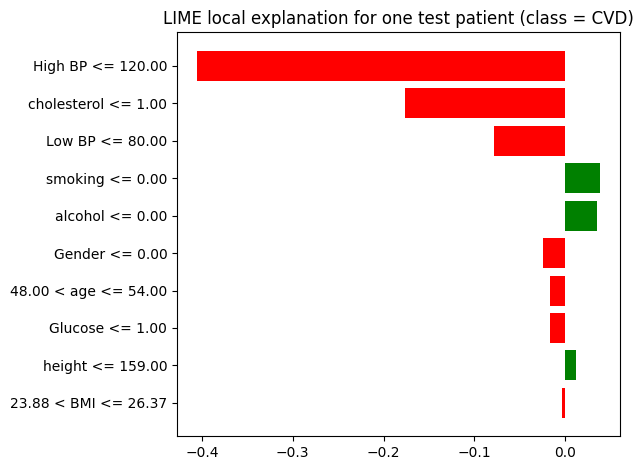

In [13]:
# Choose which test sample to explain (0 = first row in X_test)
idx = 14

# LIME expects a 1D NumPy array for the instance
x_instance = X_test_np[idx]

# Use model.predict_proba from the trained pipeline
lime_exp = lime_explainer.explain_instance(
    data_row   = x_instance,
    predict_fn = model.predict_proba,
    num_features = 10,  # top features to show
    top_labels   = 2    # focus on the most probable class (changed from 1 to 2)
)

# Plot LIME explanation as a bar chart for class "CVD (1)"
fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME local explanation for one test patient (class = CVD)")
plt.tight_layout()
plt.show()

***iii. Turn the LIME explanation into a table***

In [14]:
# LIME gives a list of (feature, weight) pairs
lime_list = lime_exp.as_list(label=1)

lime_df = pd.DataFrame(lime_list, columns=["Feature (LIME condition)", "LIME weight"])

# Add the actual feature values of this patient
patient_series = X_test.iloc[idx]
patient_dict   = patient_series.to_dict()

# Extract plain feature name from the text in "Feature (LIME condition)"
# e.g. "age > 55.00" -> "age"
def extract_feature_name(lime_cond):
    return lime_cond.split()[0]

lime_df["Feature"] = lime_df["Feature (LIME condition)"].apply(extract_feature_name)
lime_df["Patient value"] = lime_df["Feature"].map(patient_dict)

# Reorder columns
lime_df = lime_df[["Feature", "Patient value", "Feature (LIME condition)", "LIME weight"]]

print(lime_df)

       Feature  Patient value Feature (LIME condition)  LIME weight
0         High            NaN        High BP <= 120.00    -0.405164
1  cholesterol            1.0      cholesterol <= 1.00    -0.176733
2          Low            NaN          Low BP <= 80.00    -0.078513
3      smoking            0.0          smoking <= 0.00     0.037922
4      alcohol            0.0          alcohol <= 0.00     0.034872
5       Gender            0.0           Gender <= 0.00    -0.024379
6        48.00            NaN     48.00 < age <= 54.00    -0.017054
7      Glucose            1.0          Glucose <= 1.00    -0.016549
8       height          158.0         height <= 159.00     0.011398
9        23.88            NaN     23.88 < BMI <= 26.37    -0.003246


In [15]:
lime_df.to_csv("lime_example_patient.csv", index=False)

***12. Fairness: metrics by gender***

In [16]:
def group_metrics(group_value, group_name):
    mask = X_test["Gender"] == group_value

    y_true_g = y_test[mask]
    y_pred_g = y_pred[mask]
    y_proba_g = y_proba[mask]

    print(f"\n=== Metrics for {group_name} (Gender = {group_value}) ===")
    print("Samples in test set:", len(y_true_g))

    acc_g  = accuracy_score(y_true_g, y_pred_g)
    prec_g = precision_score(y_true_g, y_pred_g)
    rec_g  = recall_score(y_true_g, y_pred_g)

    tn, fp, fn, tp = confusion_matrix(y_true_g, y_pred_g).ravel()
    fpr_g = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    tpr_g = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    try:
        auc_g = roc_auc_score(y_true_g, y_proba_g)
    except ValueError:
        auc_g = float("nan")

    pos_rate = (y_pred_g == 1).mean()

    print(f"Accuracy      : {acc_g:.3f}")
    print(f"Precision     : {prec_g:.3f}")
    print(f"Recall (TPR)  : {rec_g:.3f}")
    print(f"False Pos Rate: {fpr_g:.3f}")
    print(f"Positive rate : {pos_rate:.3f}")
    print(f"AUC           : {auc_g:.3f}")

group_metrics(0, "Female")
group_metrics(1, "Male")


=== Metrics for Female (Gender = 0) ===
Samples in test set: 9119
Accuracy      : 0.733
Precision     : 0.736
Recall (TPR)  : 0.714
False Pos Rate: 0.248
Positive rate : 0.477
AUC           : 0.801

=== Metrics for Male (Gender = 1) ===
Samples in test set: 4760
Accuracy      : 0.742
Precision     : 0.762
Recall (TPR)  : 0.724
False Pos Rate: 0.240
Positive rate : 0.489
AUC           : 0.805


***13. Permutation feature importance***

High BP        0.197440
cholesterol    0.034323
age            0.034099
weight(kg)     0.006414
BMI            0.003396
Glucose        0.003336
Low BP         0.003012
active         0.001859
height         0.001504
smoking        0.000978
alcohol        0.000647
Gender         0.000487
dtype: float64


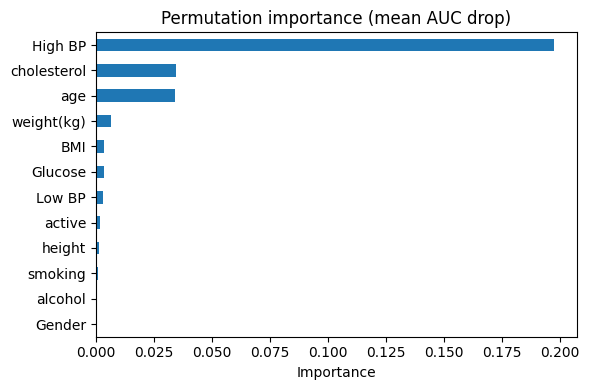

In [17]:
result_perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42
)

perm_importance = pd.Series(result_perm.importances_mean,
                            index=feature_cols).sort_values(ascending=False)

print(perm_importance)

plt.figure(figsize=(6, 4))
perm_importance.head(12).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Permutation importance (mean AUC drop)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

***14. Partial dependence plots (PDP)***

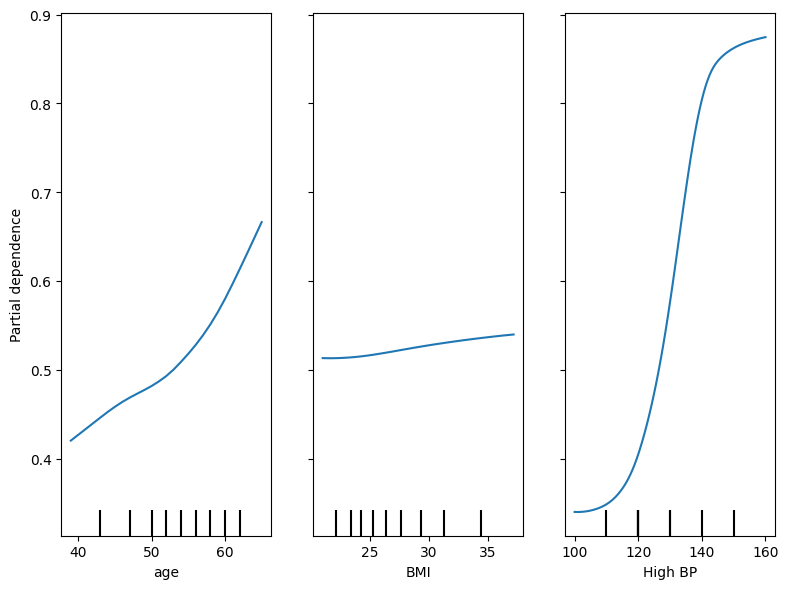

In [18]:
features_to_plot = ["age", "BMI", "High BP"]

fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(
    model,
    X_train,
    features_to_plot,
    kind="average",
    ax=ax
)
plt.tight_layout()
plt.show()

***15. SHAP: set up explainer***

In [ ]:
shap.initjs()

X_background = X_train.sample(300, random_state=42)

explainer = shap.Explainer(model.predict_proba, X_background)
class_idx = 1  # 1 = has cardiovascular disease

X_explain = X_test.copy()
shap_values = explainer(X_explain)   # shape: (n_samples, 2, n_features)
print("SHAP values shape:", shap_values.values.shape)

PermutationExplainer explainer: 13880it [14:52, 15.46it/s]                           


SHAP values shape: (13879, 12, 2)


***16. Global SHAP values for CVD = 1***

In [ ]:
X_explain = X_test.copy()
shap_values_all = explainer(X_explain)          # shape: (n_samples, 2, n_features)
shap_values_cvd = shap_values_all[..., 1]      # Explanation for class 1

print("shap_values_cvd shape:", shap_values_cvd.values.shape)

PermutationExplainer explainer: 13880it [14:25, 15.83it/s]                           


shap_values_cvd shape: (13879, 12)


# 17. SHAP plots

*i. Waterfall plot (one patient)*

Gender           0.000000
age             54.000000
height         158.000000
weight(kg)      62.000000
BMI             24.835763
High BP        120.000000
Low BP          70.000000
cholesterol      1.000000
Glucose          1.000000
smoking          0.000000
alcohol          0.000000
active           1.000000
Name: 27249, dtype: float64


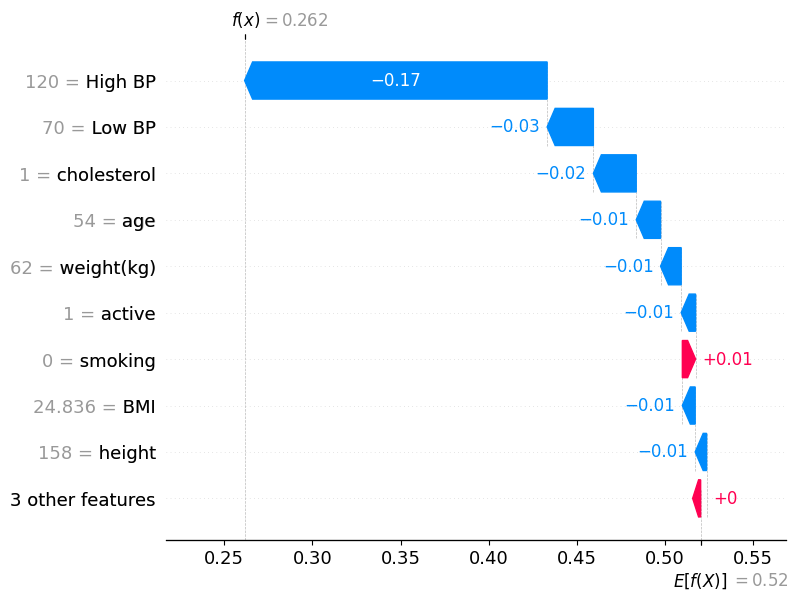

In [ ]:
#idx = 14  # which test sample to explain
print(X_test.iloc[idx])    # see the actual row used
shap.plots.waterfall(shap_values_cvd[idx], max_display=10)

*ii. Force plot (one patient)*

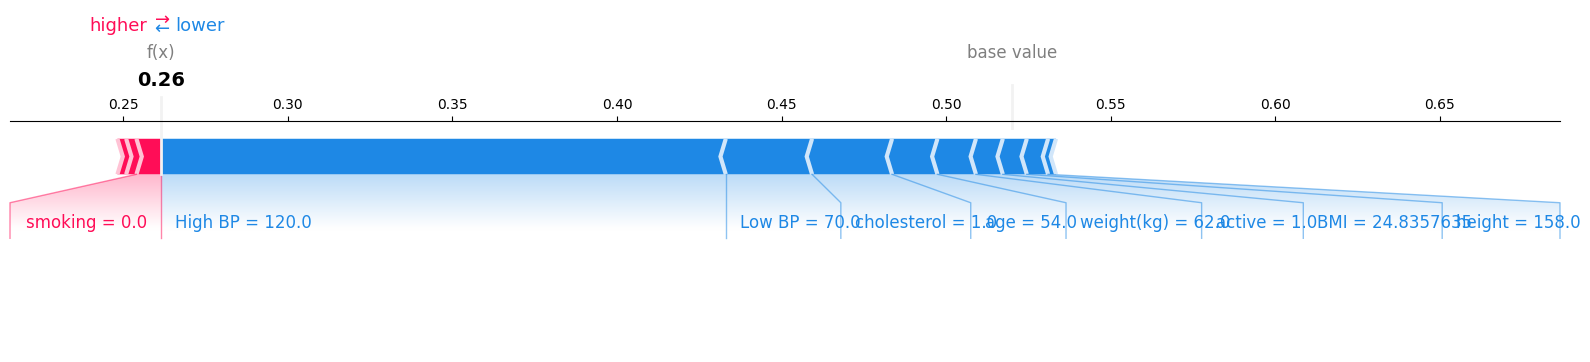

In [ ]:
shap.plots.force(shap_values_cvd[idx], matplotlib=True)

*iii. Stacked force plot (many patients – JS)*

In [ ]:
shap.initjs()  # optional, for JS plots – not strictly needed for text output
shap.plots.force(shap_values_cvd[:50])

*iv. Absolute mean SHAP (global importance bar plot)*

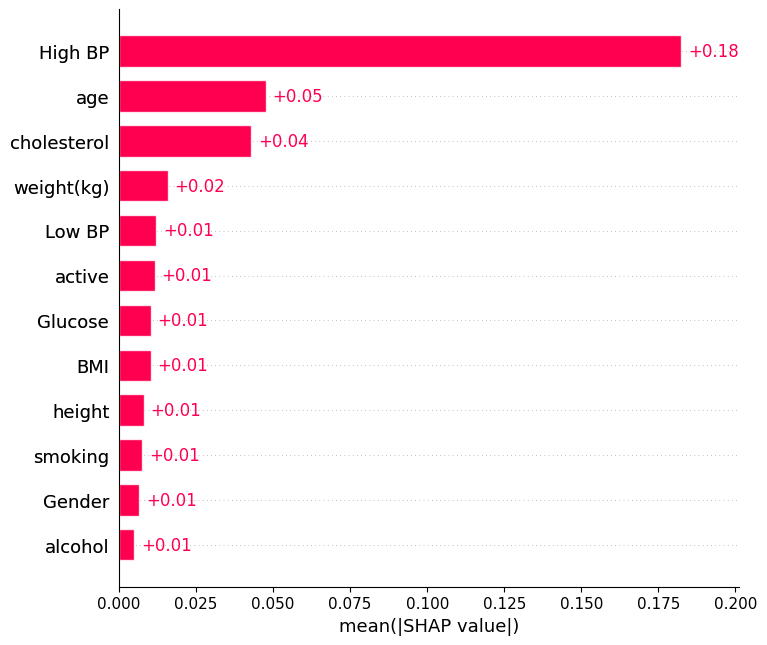

In [ ]:
shap.plots.bar(shap_values_cvd, max_display=12)

*v. Beeswarm plot (global overview)*

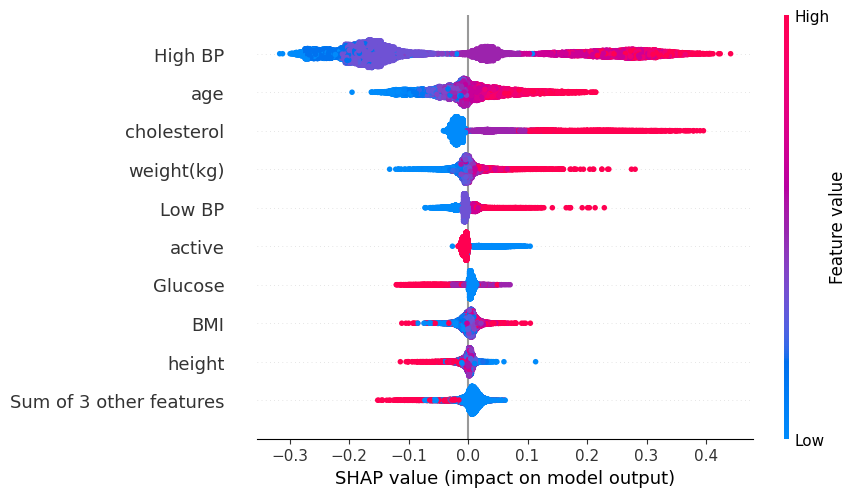

In [ ]:
shap.plots.beeswarm(shap_values_cvd)

*vi. Dependence plot (SHAP vs feature value)*

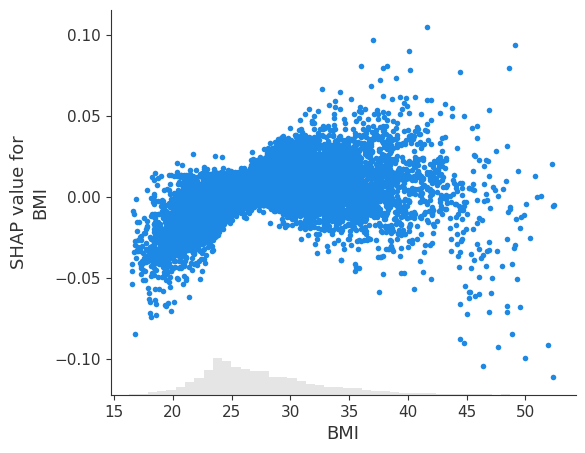

In [ ]:
shap.plots.scatter(shap_values_cvd[:, "BMI"])   # SHAP vs BMI value

*vii. Coloured by another feature (e.g., age)*

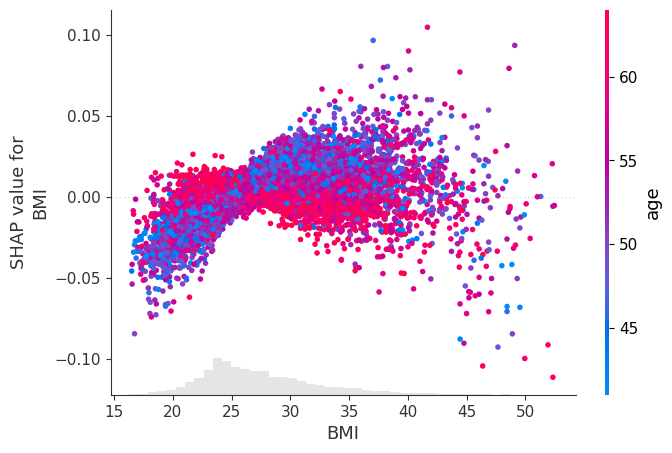

In [ ]:
shap.plots.scatter(
    shap_values_cvd[:, "BMI"],
    color=shap_values_cvd[:, "age"])

***18. Function: explain a person from raw values***

In [ ]:
def predict_and_explain_from_values(values, top_n=5):
    """
    values: list or tuple of 12 numbers in this exact order:
        [Gender, age, height, weight(kg), BMI,
         High BP, Low BP, cholesterol, Glucose,
         smoking, alcohol, active]
    """

    # 1) Put the values into a 1-row DataFrame with correct column names
    X_new = pd.DataFrame([values], columns=feature_cols)

    # 2) Model prediction
    proba = model.predict_proba(X_new)[0, class_idx]
    pred_label = int(proba >= 0.5)

    print("=== Prediction for this person ===")
    print(f"Probability of cardiovascular disease: {proba:.3f}")
    print("Prediction:", "HAS disease (1)" if pred_label == 1 else "NO disease (0)")
    print()

    # 3) SHAP explanation for this one person
    shap_single = explainer(X_new)            # shape: (1, 2, n_features)
    sv = shap_single.values[0, class_idx, :]  # SHAP values for class 1

    contributions = []
    for name, shap_val, feat_val in zip(feature_cols, sv, X_new.iloc[0]):
        contributions.append((name, shap_val, feat_val))

    contributions_sorted = sorted(contributions,
                                  key=lambda x: abs(x[1]),
                                  reverse=True)

    print(f"Top {top_n} features affecting this prediction:")
    for name, shap_val, feat_val in contributions_sorted[:top_n]:
        direction = "↑ increases risk" if shap_val > 0 else "↓ decreases risk"
        print(f"  {name} = {feat_val}  |  SHAP = {shap_val:.4f}  → {direction}")

***20. Manually-entered patient data***

In [ ]:
predict_and_explain_from_values(
    [1, 62, 178, 95.0, 29.967120, 130, 90, 3, 3, 0, 0, 1],
    top_n=5)